# Download a subset of ReLAION-high-resolution

The dataset contains only image **URLs** and metadata (parquet shards), not the images themselves,
so we have to fetch every image from its original host. Many links are dead, so `NUM_IMAGES` is the
number of images that must be **successfully downloaded**, not the number of links to try.

The notebook downloads images concurrently with `aiohttp` and reports:

1. average download throughput (successful images per second),
2. share of dead links with a breakdown by failure reason.

Optimizations used: one shared connection pool with DNS cache, per-host connection limit
(to be polite and avoid bans), hundreds of concurrent requests, streaming reads with a size cap,
raw bytes saved without re-encoding, fast `PIL.verify()` instead of full decode, shuffled URLs
so requests spread across many hosts.

The dataset is gated: accept the terms on its Hugging Face page and run `hf auth login` first.

In [1]:
import asyncio
import io
import random
import time
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import aiohttp
import pyarrow.parquet as pq
from huggingface_hub import HfApi, hf_hub_download
from PIL import Image
from tqdm.auto import tqdm

DATASET_NAME: str = "laion/relaion-high-resolution"
NUM_IMAGES: int = 1000
SHARD_INDEX: int = 0
URL_COLUMN: str | None = None
SEED: int = 0
OUTPUT_DIRECTORY: Path = Path("../datasets/relaion_high_resolution_subset")

CONCURRENCY: int = 256
MAX_CONNECTIONS_PER_HOST: int = 4
CONNECT_TIMEOUT_SECONDS: float = 5.0
TOTAL_TIMEOUT_SECONDS: float = 20.0
MAX_IMAGE_BYTES: int = 30 * 1024 * 1024
VERIFY_SSL: bool = False
USER_AGENT: str = "Mozilla/5.0 (X11; Linux x86_64) research-dataset-downloader"

## Load one metadata shard

A single shard has millions of rows, which is more than enough links for a small subset.
Increase `SHARD_INDEX` or switch shards if `NUM_IMAGES` is very large.

In [2]:
repository_files: list[str] = sorted(
    file_name
    for file_name in HfApi().list_repo_files(DATASET_NAME, repo_type="dataset")
    if file_name.endswith(".parquet")
)
shard_path: str = hf_hub_download(DATASET_NAME, repository_files[SHARD_INDEX], repo_type="dataset")
shard_table = pq.read_table(shard_path)
print(f"{len(repository_files)} shards, using {repository_files[SHARD_INDEX]}")
print(f"{shard_table.num_rows} rows, columns: {shard_table.column_names}")

128 shards, using part-00000-45914064-d424-4c1c-8d96-dc8125c645fb-c000.snappy.parquet
1298172 rows, columns: ['URL', 'TEXT', 'WIDTH', 'HEIGHT', 'similarity', 'LANGUAGE', 'hash', 'pwatermark', 'punsafe']


In [3]:
url_column: str = URL_COLUMN or next(
    column_name for column_name in shard_table.column_names if column_name.lower() == "url"
)
image_urls: list[str] = shard_table.column(url_column).to_pylist()
random.Random(SEED).shuffle(image_urls)
print(f"{len(image_urls)} candidate urls, example: {image_urls[0]}")

1298172 candidate urls, example: https://s0.wklcdn.com/image_57/1736868/38425965/24883272Master.jpg


## Downloader

Each worker pulls the next URL from a shared iterator until `NUM_IMAGES` successes are reached.
Every attempt gets exactly one outcome label, so dead-link statistics are exact.

In [4]:
@dataclass
class DownloadResult:
    url: str
    outcome: str
    byte_count: int = 0
    width: int = 0
    height: int = 0
    extension: str = ""
    content: bytes = b""


async def fetch_image(session: aiohttp.ClientSession, url: str) -> DownloadResult:
    """Download and validate one image. Outcome is "ok" or a failure reason."""
    try:
        async with session.get(url) as response:
            if response.status != 200:
                return DownloadResult(url, f"http_{response.status}")
            content_length: int = response.content_length or 0
            if content_length > MAX_IMAGE_BYTES:
                return DownloadResult(url, "too_large")
            buffer = bytearray()
            async for chunk in response.content.iter_chunked(64 * 1024):
                buffer.extend(chunk)
                if len(buffer) > MAX_IMAGE_BYTES:
                    return DownloadResult(url, "too_large")
    except asyncio.TimeoutError:
        return DownloadResult(url, "timeout")
    except aiohttp.ClientConnectorError:
        return DownloadResult(url, "connection_or_dns_error")
    except aiohttp.ClientError:
        return DownloadResult(url, "client_error")
    except Exception:
        return DownloadResult(url, "other_error")

    try:
        with Image.open(io.BytesIO(buffer)) as image:
            image.verify()
            width, height = image.size
            extension: str = (image.format or "jpeg").lower().replace("jpeg", "jpg")
    except Exception:
        return DownloadResult(url, "not_a_valid_image", byte_count=len(buffer))

    return DownloadResult(url, "ok", len(buffer), width, height, extension, bytes(buffer))


async def download_images(
    urls: list[str], num_images: int, output_directory: Path
) -> tuple[list[DownloadResult], float]:
    """
    Download until num_images succeed or urls run out.
    Returns all attempt results and elapsed wall-clock seconds.
    """
    output_directory.mkdir(parents=True, exist_ok=True)
    connector = aiohttp.TCPConnector(
        limit=CONCURRENCY,
        limit_per_host=MAX_CONNECTIONS_PER_HOST,
        ttl_dns_cache=600,
        ssl=VERIFY_SSL,
        enable_cleanup_closed=True,
    )
    timeout = aiohttp.ClientTimeout(total=TOTAL_TIMEOUT_SECONDS, connect=CONNECT_TIMEOUT_SECONDS)
    url_iterator = iter(urls)
    results: list[DownloadResult] = []
    success_count: int = 0
    progress_bar = tqdm(total=num_images, desc="downloaded")

    async def worker(session: aiohttp.ClientSession) -> None:
        nonlocal success_count
        for url in url_iterator:
            if success_count >= num_images:
                return
            result = await fetch_image(session, url)
            if result.outcome == "ok":
                if success_count >= num_images:
                    return
                file_path = output_directory / f"{success_count:07d}.{result.extension}"
                file_path.write_bytes(result.content)
                result.content = b""
                success_count += 1
                progress_bar.update(1)
            results.append(result)

    start_time: float = time.perf_counter()
    async with aiohttp.ClientSession(
        connector=connector, timeout=timeout, headers={"User-Agent": USER_AGENT}
    ) as session:
        await asyncio.gather(*(worker(session) for _ in range(CONCURRENCY)))
    elapsed_seconds: float = time.perf_counter() - start_time
    progress_bar.close()
    return results, elapsed_seconds

In [5]:
results, elapsed_seconds = await download_images(image_urls, NUM_IMAGES, OUTPUT_DIRECTORY)

downloaded:   0%|          | 0/1000 [00:00<?, ?it/s]

## Statistics

Throughput is computed over wall-clock time of the whole run, so it includes time spent on dead links.
Requests still in flight when the target is reached are discarded and not counted,
so the folder holds exactly `NUM_IMAGES` files.

In [6]:
outcome_counts: Counter[str] = Counter(result.outcome for result in results)
attempted_count: int = len(results)
success_results: list[DownloadResult] = [result for result in results if result.outcome == "ok"]
success_count: int = len(success_results)
total_megabytes: float = sum(result.byte_count for result in success_results) / 1e6

print(f"Elapsed:                {elapsed_seconds:.1f} s")
print(f"Links attempted:        {attempted_count}")
print(f"Images downloaded:      {success_count}")
print(f"Images per second:      {success_count / elapsed_seconds:.2f}")
print(f"Attempts per second:    {attempted_count / elapsed_seconds:.2f}")
print(f"Throughput:             {total_megabytes / elapsed_seconds:.2f} MB/s")
print(f"Alive links:            {100 * success_count / attempted_count:.1f}%")
print(f"Dead / invalid links:   {100 * (attempted_count - success_count) / attempted_count:.1f}%")
print(f"Mean image size:        {total_megabytes / max(success_count, 1):.2f} MB")
print()
print("Outcome breakdown:")
for outcome, count in outcome_counts.most_common():
    print(f"  {outcome:26s} {count:7d}  {100 * count / attempted_count:5.1f}%")

Elapsed:                78.6 s
Links attempted:        3975
Images downloaded:      1000
Images per second:      12.72
Attempts per second:    50.56
Throughput:             6.78 MB/s
Alive links:            25.2%
Dead / invalid links:   74.8%
Mean image size:        0.53 MB

Outcome breakdown:
  timeout                       2622   66.0%
  ok                            1000   25.2%
  http_404                       160    4.0%
  http_400                        91    2.3%
  http_403                        43    1.1%
  connection_or_dns_error         29    0.7%
  http_406                        18    0.5%
  not_a_valid_image                4    0.1%
  http_521                         3    0.1%
  client_error                     1    0.0%
  http_502                         1    0.0%
  http_401                         1    0.0%
  http_429                         1    0.0%
  http_402                         1    0.0%


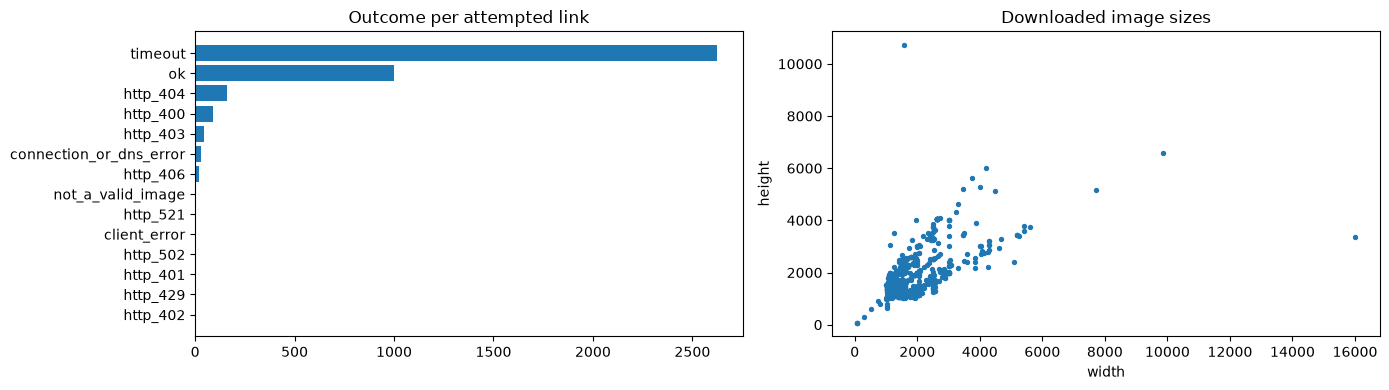

In [7]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(1, 2, figsize=(14, 4))
labels, counts = zip(*outcome_counts.most_common())
axes[0].barh(labels[::-1], counts[::-1])
axes[0].set_title("Outcome per attempted link")
axes[1].scatter(
    [result.width for result in success_results],
    [result.height for result in success_results],
    s=8,
)
axes[1].set_title("Downloaded image sizes")
axes[1].set_xlabel("width")
axes[1].set_ylabel("height")
plt.tight_layout()
plt.show()

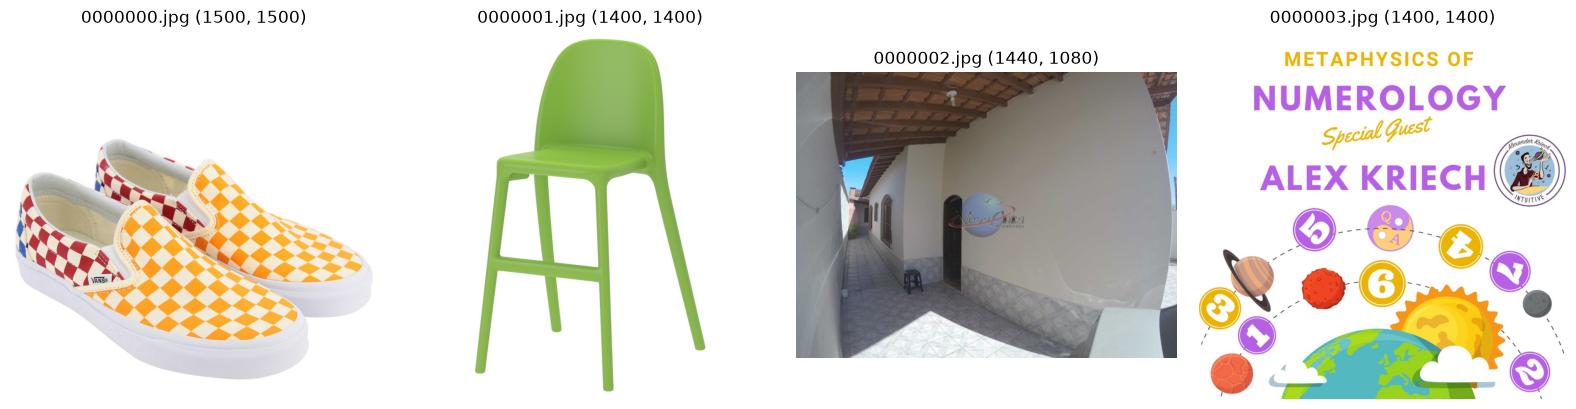

In [8]:
preview_paths: list[Path] = sorted(OUTPUT_DIRECTORY.glob("*.*"))[:4]
figure, axes = plt.subplots(1, len(preview_paths), figsize=(16, 4))
for axis, preview_path in zip(axes if len(preview_paths) > 1 else [axes], preview_paths):
    with Image.open(preview_path) as image:
        axis.imshow(image.convert("RGB"))
        axis.set_title(f"{preview_path.name} {image.size}")
    axis.axis("off")
plt.tight_layout()
plt.show()